# Proiectul #1 - Telco Customer Churn

Prezicem dacă un client părăsește operatorul de telefonie (coloana `Churn`).

## Pasul 1 - Explorarea datelor

Importăm bibliotecile de care avem nevoie, apoi încărcăm setul de date și ne uităm la dimensiunea lui și la primele rânduri.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# sns.set_theme(style="whitegrid")

df = pd.read_csv("data/telco_churn.csv")
print("Dimensiune (rânduri, coloane):", df.shape)
df.head()

Dimensiune (rânduri, coloane): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Avem 3 coloane de tip număr, `SeniorCitizen`, `tenure` și `MonthlyCharges`, restul sunt de tip string și reprezintă diverse filtre. Coloana `TotalCharges` ar trebui să fie tot număr, dar e citită ca string, de ce se întâmplă asta vedem mai jos.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Analizăm dacă coloanele noastre au date lipsă. După analiză pare că nu sunt, dar la o privire în detaliu a setului de date par niște valori lipsă la coloana `TotalCharges`. Din cauza faptului că tipul coloanei e str, spațiul gol e considerat ca valoare. Așadar verificăm câte sunt și care sunt acele rânduri care au asemenea spații libere pe coloana lor. 

In [3]:
# Valorile lipsă "oficiale" (NaN)
print("NaN pe coloane:", df.isna().sum().sum())

# TotalCharges e citită ca text: unele celule conțin doar un spațiu
goale = df["TotalCharges"].str.strip() == ""
print("TotalCharges goale:", goale.sum())
df.loc[goale, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

NaN pe coloane: 0
TotalCharges goale: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Făcând un calcul pe coloană să vedem care e valoarea celor care pleacă și a celor care rămân observăm că 73.5% rămân și 26.5% pleacă.

In [4]:
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


### Graficul 1 - Câți clienți pleacă

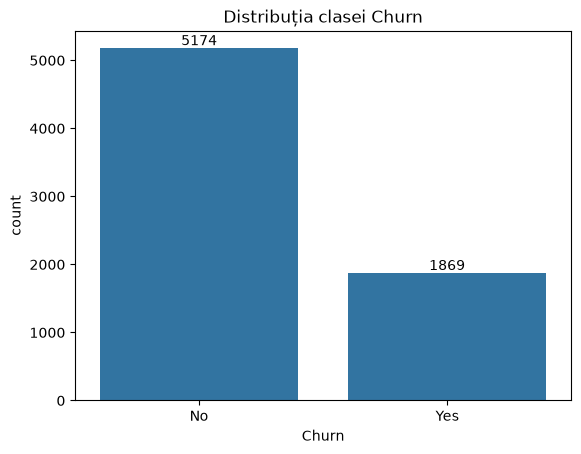

In [5]:
ax = sns.countplot(data=df, x="Churn")
ax.set_title("Distribuția clasei Churn")
ax.bar_label(ax.containers[0])   # scrie numărul de clienți deasupra fiecărei bare
plt.show()

Pe grafic se vede că cei care rămân sunt mult mai mulți decât cei care pleacă, aproape 3 la 1, deci clasele nu sunt echilibrate.

### Graficul 2 - Rata de plecare în funcție de tipul de contract

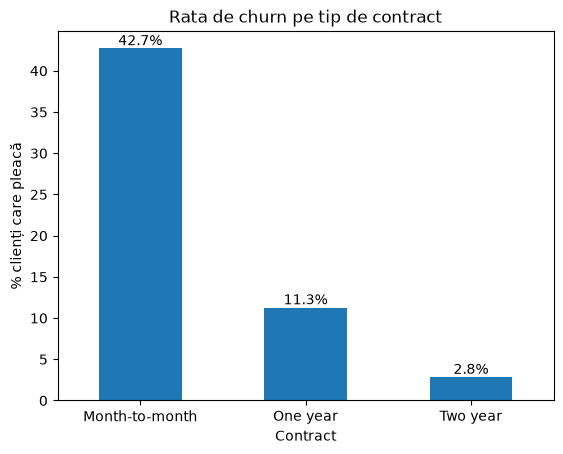

In [6]:
rata = (df.assign(pleaca=df["Churn"] == "Yes")
          .groupby("Contract")["pleaca"].mean()
          .sort_values(ascending=False) * 100)
ax = rata.plot(kind="bar", rot=0)
ax.set_ylabel("% clienți care pleacă")
ax.set_title("Rata de churn pe tip de contract")
for i, v in enumerate(rata):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.show()

Observăm pe grafic faptul că tipul de contract influențează și decizia de a păstra serviciile sau nu

### Graficul 3 - Vechimea clientului (`tenure`, în luni) pentru cei care pleacă vs. rămân

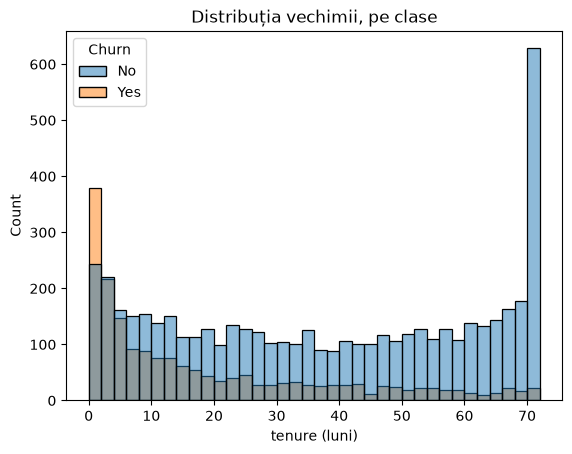

In [7]:
ax = sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="layer", stat="count")
ax.set_xlabel("tenure (luni)")
ax.set_title("Distribuția vechimii, pe clase")
plt.show()

Asemenător cu graficul tipului de contract, și aici observăm că cele mai multe plecări se fac în primele luni de utilizare a serviciului, ulterior trecând de 25 de luni, numărul celor care pleacă fiind unul foarte puțin fluctuant.

## Pasul 2 - Pregătirea datelor

Coloana `customerID` nu reprezintă nimic important ci niște id-uri ale clienților, așa că o eliminăm și apoi convertim `TotalCharges` în valori numerice și punem 0 acolo unde aveam valori lipsă.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler



df_curat = df.drop(columns="customerID")

# Textul gol devine NaN, apoi 0: sunt clienți cu tenure = 0, încă n-au plătit nimic
df_curat["TotalCharges"] = pd.to_numeric(df_curat["TotalCharges"], errors="coerce").fillna(0)

print("TotalCharges este acum:", df_curat["TotalCharges"].dtype)
print("Valori lipsă rămase:", df_curat.isna().sum().sum())

TotalCharges este acum: float64
Valori lipsă rămase: 0


Pentru a fi ușor de utilizat coloana Churn, facem encoding pe ea, astfel încât să avem
 - 1 = pleacă, 0 = rămâne

In [9]:
target = (df_curat["Churn"] == "Yes").astype(int) #comparăm valorile cu "Yes" și transformăm în 0/1 

X = df_curat.drop(columns="Churn")

X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.2, stratify=target, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporția celor care pleacă în train:", round(y_train.mean(), 3))
print("Proporția celor care pleacă în test: ", round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19)
Proporția celor care pleacă în train: 0.265
Proporția celor care pleacă în test:  0.265


Modelele lucrează doar cu numere, așa că transformăm coloanele text cu one-hot, adică fiecare valoare posibilă devine o coloană separată cu 0 sau 1. Coloanele numerice le scalăm ca să fie toate pe aceeași scară, cu media 0 și deviația 1, astfel încât o coloană cu valori mari, cum e `TotalCharges`, să nu conteze mai mult doar pentru că are numere mai mari.

In [10]:
col_numerice = X.select_dtypes(include="number").columns.tolist()
col_categorice = [c for c in X.columns if c not in col_numerice]
print("Coloane numerice:", col_numerice)
print("Coloane categorice:", col_categorice)

def fa_preprocesare():
    return ColumnTransformer([
        ("num", StandardScaler(), col_numerice),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), col_categorice),
    ])

Coloane numerice: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Coloane categorice: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Apoi facem fit_transform pe train pentru a învăța media și deviația de la fiecare coloană numerică, apoi aplică ce a învățat pe train. Iar la test aplică direct ceea ce a învățat în train, pentru că datele de test sunt practic clienții noi și nu trebuie să influențeze nimic din ce învață modelul, altfel am avea data leakage.

In [11]:
prep = fa_preprocesare()
X_train_prep = prep.fit_transform(X_train)   # învață media/deviația și categoriile DOAR din train
X_test_prep = prep.transform(X_test)         # aplică pe test exact aceleași reguli

print("Coloane după one-hot:", X_train_prep.shape[1])
print("Exemplu de coloane noi:", list(prep.get_feature_names_out()[4:10]))
print("Media tenure în train după scalare:", round(X_train_prep[:, 1].mean(), 3))

Coloane după one-hot: 45
Exemplu de coloane noi: ['cat__gender_Female', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes']
Media tenure în train după scalare: -0.0


## Pasul 3 - Baseline

Folosim un model prost, care nu învață nimic din date, îl folosim ca model de referință. Pentru asta luăm un `DummyClassifier(strategy="most_frequent")` care ne prezice mereu clasa cea mai des întâlnită, aici clasa rămâne (0).

In [12]:
import warnings
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

baseline = DummyClassifier(strategy="most_frequent")   # prezice mereu clasa cea mai des întâlnită
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

print("Accuracy: ", round(accuracy_score(y_test, pred_baseline), 3))
print("Precision:", round(precision_score(y_test, pred_baseline, zero_division=0), 3))
print("Recall:   ", round(recall_score(y_test, pred_baseline), 3))
print("F1:       ", round(f1_score(y_test, pred_baseline), 3))

Accuracy:  0.735
Precision: 0.0
Recall:    0.0
F1:        0.0


## Pasul 4 - Antrenarea modelelor

Antrenăm trei modele, regresie logistică, Random Forest și XGBoost. Regresia logistică dă câte o greutate fiecărei coloane, Random Forest face 300 de arbori de decizie care votează, iar XGBoost face arborii pe rând, fiecare încercând să corecteze greșelile celor de dinainte. Din cauza faptului că avem mult mai puțini clienți care pleacă, folosim `class_weight="balanced"`, iar la XGBoost echivalentul lui, `scale_pos_weight`, astfel încât greșelile pe cei care pleacă să conteze mai mult. Preprocesarea și modelul le punem în același `Pipeline` ca scalarea și encodarea să învețe doar din datele de antrenare, așa nu avem data leakage.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# câți clienți rămân pentru fiecare client care pleacă (~2.8) - folosit de XGBoost pentru echilibrare
pondere = (y_train == 0).sum() / (y_train == 1).sum()

modele = {
    "Regresie logistică": LogisticRegression(max_iter=1000, class_weight="balanced"),
    
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),

    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=pondere, random_state=RANDOM_STATE, n_jobs=-1),
}

pipelines = {nume: Pipeline([("prep", fa_preprocesare()), ("model", m)])
             for nume, m in modele.items()}
print("Modele pregătite:", list(pipelines))

Modele pregătite: ['Regresie logistică', 'Random Forest', 'XGBoost']


Ca să comparăm modelele nu folosim setul de test, pe acela îl păstrăm pentru final. Așadar folosim cross-validation, care împarte datele de train în 5 bucăți, antrenează pe 4 și testează pe a 5-a, de 5 ori, iar la final facem media scorurilor.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rezultate_cv = []
for nume, pipe in pipelines.items():
    scoruri = cross_validate(pipe, X_train, y_train, cv=cv,
                             scoring=["recall", "precision", "f1", "roc_auc"])
    rezultate_cv.append({
        "model": nume,
        "recall": scoruri["test_recall"].mean(),
        "precision": scoruri["test_precision"].mean(),
        "f1": scoruri["test_f1"].mean(),
        "f1 ± std": scoruri["test_f1"].std(),
        "roc_auc": scoruri["test_roc_auc"].mean(),
    })

pd.DataFrame(rezultate_cv).set_index("model").round(3)

,recall,precision,f1,f1 ± std,roc_auc
model,,,,,
Regresie logistică,0.801,0.517,0.628,0.023,0.846
Random Forest,0.762,0.540,0.632,0.016,0.845
XGBoost,0.773,0.533,0.631,0.015,0.844


### GridSearchCV pentru Random Forest

Cu `GridSearchCV` încercăm toate combinațiile de parametri din grilă pentru Random Forest, în cazul nostru 9 combinații. Fiecare combinație e verificată cu cross-validation și la final o păstrăm pe cea care are cel mai bun F1.

In [15]:
from sklearn.model_selection import GridSearchCV

grila = {
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [1, 5, 20],
}
search = GridSearchCV(pipelines["Random Forest"], grila, cv=cv, scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)

print("Cel mai bun F1 (CV):", round(search.best_score_, 3))
print("Parametri:", search.best_params_)
pipelines["Random Forest (tunat)"] = search.best_estimator_

Cel mai bun F1 (CV): 0.632
Parametri: {'model__max_depth': None, 'model__min_samples_leaf': 5}


## Pasul 5 - Evaluarea pe setul de test

Antrenăm fiecare model pe tot setul de train, apoi îl verificăm o singură dată pe setul de test, împreună cu baseline-ul, ca să vedem cum se descurcă pe clienți pe care nu i-a mai văzut.

In [16]:
rezultate_test = [{
    "model": "Baseline (Dummy)",
    "accuracy": accuracy_score(y_test, pred_baseline),
    "recall": recall_score(y_test, pred_baseline),
    "precision": precision_score(y_test, pred_baseline, zero_division=0),
    "f1": f1_score(y_test, pred_baseline),
    "roc_auc": 0.5,
}]
predictii = {}

for nume, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]   # probabilitatea ca clientul să plece
    predictii[nume] = pred
    rezultate_test.append({
        "model": nume,
        "accuracy": accuracy_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

tabel_test = pd.DataFrame(rezultate_test).set_index("model").round(3)
tabel_test

,accuracy,recall,precision,f1,roc_auc
model,,,,,
Baseline (Dummy),0.735,0.000,0.000,0.000,0.500
Regresie logistică,0.738,0.783,0.504,0.614,0.842
Random Forest,0.764,0.775,0.539,0.636,0.841
XGBoost,0.752,0.770,0.522,0.622,0.840
Random Forest (tunat),0.764,0.775,0.539,0.636,0.841


Matricea de confuzie ne arată unde greșește fiecare model. Pe rânduri avem ce s-a întâmplat în realitate, iar pe coloane ce a prezis modelul. Cel mai mult ne interesează colțul din stânga jos, adică clienții care pleacă dar modelul zice că rămân, practic clienții pe care îi pierdem. La Random Forest observăm că din 374 de clienți care pleacă a prins 290 și a ratat 84, iar 248 de clienți care rămân au fost marcați greșit că pleacă.

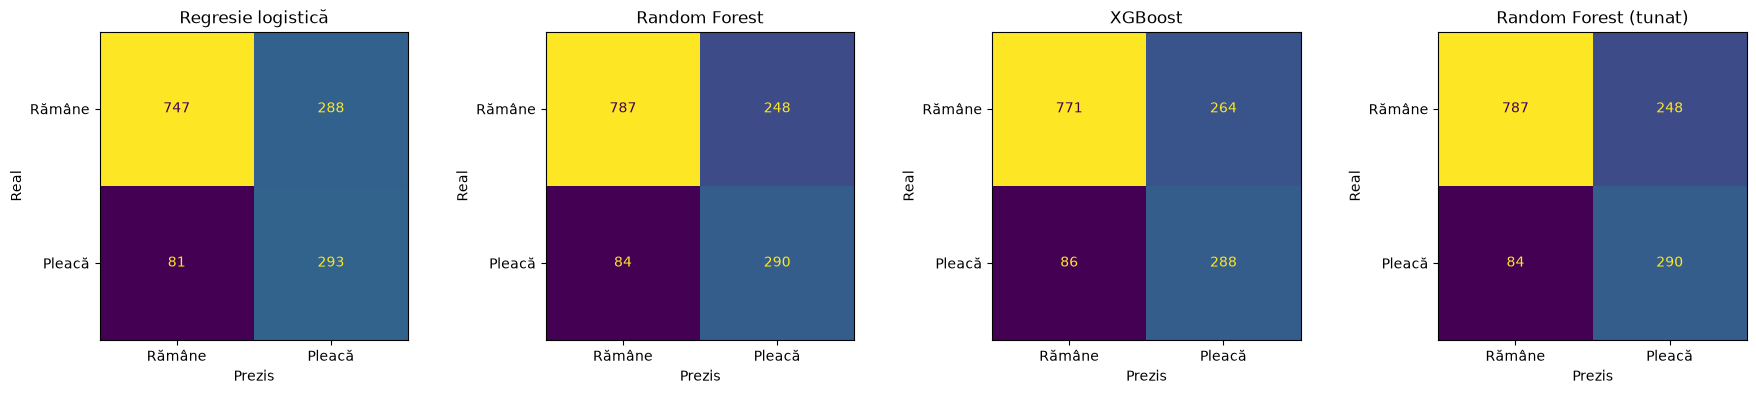

In [17]:
fig, axes = plt.subplots(1, len(predictii), figsize=(4.5 * len(predictii), 4))
for ax, (nume, pred) in zip(axes, predictii.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Rămâne", "Pleacă"]).plot(ax=ax, colorbar=False)
    ax.set_title(nume)
    ax.set_xlabel("Prezis")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

Pentru Random Forest, din clienții care pleacă modelul prinde 78%, adică recall-ul de 0.78, iar din cei despre care zice că pleacă, 54% chiar pleacă. La clienții care rămân modelul e mult mai sigur, precision-ul fiind de 0.90.

In [18]:
cel_mai_bun = tabel_test.drop(index="Baseline (Dummy)")["f1"].idxmax()
print("Modelul cu cel mai bun F1 pe test:", cel_mai_bun)
print()
print(classification_report(y_test, predictii[cel_mai_bun], target_names=["Rămâne", "Pleacă"]))

Modelul cu cel mai bun F1 pe test: Random Forest

              precision    recall  f1-score   support

      Rămâne       0.90      0.76      0.83      1035
      Pleacă       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



## Bonus - Ce coloane contează (feature importance)

Pe grafic observăm că Random Forest s-a bazat cel mai mult pe vechimea clientului, pe contractul lunar și pe suma totală plătită, la fel ca în graficele de la Pasul 1. Coloane ca `PhoneService` aproape nu contează în decizie.

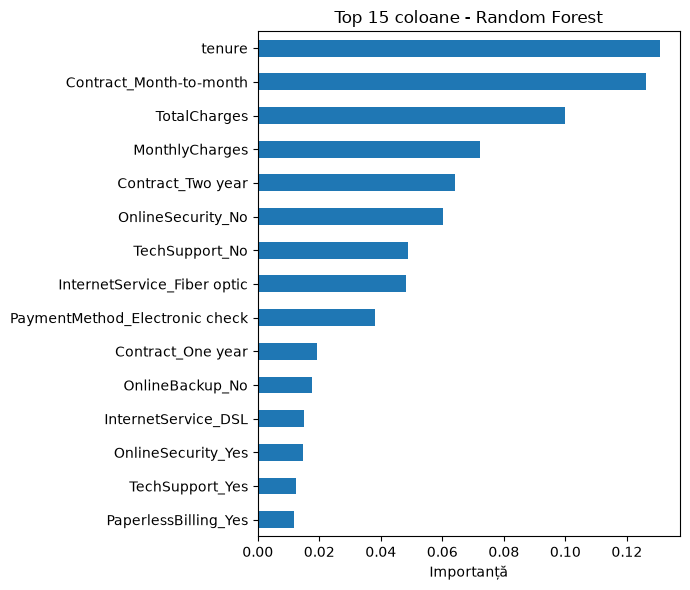

In [19]:
rf = pipelines["Random Forest (tunat)"]
importante = pd.Series(rf.named_steps["model"].feature_importances_,
                       index=rf.named_steps["prep"].get_feature_names_out())
importante.index = importante.index.str.replace("num__", "").str.replace("cat__", "")

ax = importante.sort_values().tail(15).plot(kind="barh", figsize=(7, 6))
ax.set_title("Top 15 coloane - Random Forest")
ax.set_xlabel("Importanță")
plt.tight_layout()
plt.show()

## Bonus - Selecția de features

Aici păstrăm doar cele mai bune k coloane din cele 45 și ne uităm ce se întâmplă cu F1. Selecția e pusă în Pipeline, deci învață tot doar din train. Observăm că la 30, 20 sau chiar 10 coloane F1-ul rămâne aproape la fel, în jur de 0.62, și abia la 5 coloane scade. Practic coloanele slabe nu încurcă modelul, iar cu mai puține coloane modelul ar fi la fel de bun și mai ușor de explicat.

In [20]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import cross_val_score

def scor_mi(X, y):
    return mutual_info_classif(X, y, random_state=RANDOM_STATE)

selectie = []
for k in ["all", 30, 20, 10, 5]:
    pipe = Pipeline([
        ("prep", fa_preprocesare()),
        ("select", SelectKBest(scor_mi, k=k)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    selectie.append({"coloane păstrate": k, "f1 (CV)": f1.mean(), "± std": f1.std()})

pd.DataFrame(selectie).round(3)

,coloane păstrate,f1 (CV),± std
0,all,0.628,0.023
1,30,0.624,0.017
2,20,0.624,0.017
3,10,0.623,0.020
4,5,0.606,0.016


## Pasul 6 - Concluzie

**Ce model recomandați?** Recomand Random Forest, pentru că are cel mai bun F1, de 0.636, și cea mai bună precision pe test și prinde 78% din clienții care pleacă. Regresia logistică e foarte aproape și e mai simplă de explicat, deci ar fi și ea o variantă bună.

**Cât de mult bate baseline-ul?** Baseline-ul nu prinde niciun client care pleacă, are recall și F1 0, pe când Random Forest prinde 290 din 374, cu un recall de 0.775 și F1 de 0.636. La accuracy diferența e mică, de la 73.5% la 76.4%, ceea ce arată încă o dată că accuracy nu e metrica bună aici.

**O limitare a analizei:** Diferențele dintre modele sunt foarte mici, cam cât variază scorul între fold-uri, deci nu putem fi siguri că Random Forest e cu adevărat cel mai bun. De asemenea pragul de decizie a rămas 0.5, iar dacă am ști cât costă de fapt un client pierdut și o reducere, l-am putea ajusta.